<a href="https://colab.research.google.com/github/Bousara/turbofan-predictive-maintenance/blob/main/notebooks/01_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Bonjour, le projet commence !")

Bonjour, le projet commence !


In [2]:
import kagglehub

chemin = kagglehub.dataset_download("behrad3d/nasa-cmaps")
print("Données téléchargées ici :", chemin)

100%|██████████| 12.3M/12.3M [00:02<00:00, 6.17MB/s]

Extracting files...


Données téléchargées ici : /root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1


In [3]:
import os

for dossier, sous_dossiers, fichiers in os.walk(chemin):
    for f in fichiers:
        print(os.path.join(dossier, f))

/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/train_FD001.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/RUL_FD002.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/train_FD004.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/test_FD004.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/train_FD003.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/Damage Propagation Modeling.pdf
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/test_FD002.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/test_FD003.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/x.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/RUL_FD001.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/train_FD002.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMa

In [4]:
import pandas as pd

dossier = os.path.join(chemin, "CMaps")

colonnes = ["moteur", "cycle", "reglage_1", "reglage_2", "reglage_3"] + \
           [f"capteur_{i}" for i in range(1, 22)]

train = pd.read_csv(os.path.join(dossier, "train_FD001.txt"),
                    sep=r"\s+", header=None, names=colonnes)

train.head()

,moteur,cycle,reglage_1,reglage_2,reglage_3,capteur_1,capteur_2,capteur_3,capteur_4,capteur_5,...,capteur_12,capteur_13,capteur_14,capteur_15,capteur_16,capteur_17,capteur_18,capteur_19,capteur_20,capteur_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [5]:
print(train.shape)
print("Nombre de moteurs :", train["moteur"].nunique())

(20631, 26)
Nombre de moteurs : 100


In [6]:
dernier_cycle = train.groupby("moteur")["cycle"].transform("max")
train["RUL"] = dernier_cycle - train["cycle"]

In [7]:
moteur_1 = train[train["moteur"] == 1]
print(moteur_1[["moteur", "cycle", "RUL"]].head())
print(moteur_1[["moteur", "cycle", "RUL"]].tail())

   moteur  cycle  RUL
0       1      1  191
1       1      2  190
2       1      3  189
3       1      4  188
4       1      5  187
     moteur  cycle  RUL
187       1    188    4
188       1    189    3
189       1    190    2
190       1    191    1
191       1    192    0


In [8]:
duree_vie = train.groupby("moteur")["cycle"].max()

print("Plus courte :", duree_vie.min(), "cycles")
print("Plus longue :", duree_vie.max(), "cycles")
print("Moyenne :", round(duree_vie.mean()), "cycles")

Plus courte : 128 cycles
Plus longue : 362 cycles
Moyenne : 206 cycles


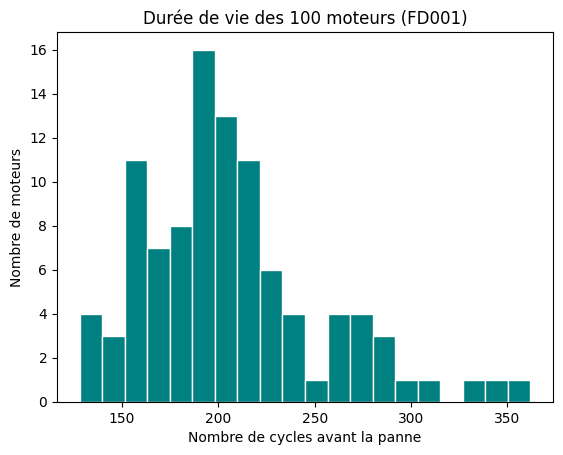

In [9]:
import matplotlib.pyplot as plt

plt.hist(duree_vie, bins=20, color="teal", edgecolor="white")
plt.xlabel("Nombre de cycles avant la panne")
plt.ylabel("Nombre de moteurs")
plt.title("Durée de vie des 100 moteurs (FD001)")
plt.show()

In [10]:
capteurs = [f"capteur_{i}" for i in range(1, 22)]

ecarts = train[capteurs].std().sort_values()
print(ecarts)

capteur_19    0.000000e+00
capteur_18    0.000000e+00
capteur_16    1.556432e-14
capteur_10    4.660829e-13
capteur_5     3.394700e-12
capteur_1     6.537152e-11
capteur_6     1.388985e-03
capteur_15    3.750504e-02
capteur_8     7.098548e-02
capteur_13    7.191892e-02
capteur_21    1.082509e-01
capteur_20    1.807464e-01
capteur_11    2.670874e-01
capteur_2     5.000533e-01
capteur_12    7.375534e-01
capteur_7     8.850923e-01
capteur_17    1.548763e+00
capteur_3     6.131150e+00
capteur_4     9.000605e+00
capteur_14    1.907618e+01
capteur_9     2.208288e+01
dtype: float64


In [11]:
a_retirer = ["capteur_1", "capteur_5", "capteur_6", "capteur_10",
             "capteur_16", "capteur_18", "capteur_19"]

capteurs_utiles = [c for c in capteurs if c not in a_retirer]
print(len(capteurs_utiles), "capteurs gardés :", capteurs_utiles)

14 capteurs gardés : ['capteur_2', 'capteur_3', 'capteur_4', 'capteur_7', 'capteur_8', 'capteur_9', 'capteur_11', 'capteur_12', 'capteur_13', 'capteur_14', 'capteur_15', 'capteur_17', 'capteur_20', 'capteur_21']


In [12]:
neuf = train[train["RUL"] > 150]
fin = train[train["RUL"] < 10]

print("Capteur 8 — neuf :", round(neuf["capteur_8"].mean(), 3),
      "| fin :", round(fin["capteur_8"].mean(), 3))
print("Capteur 6 — neuf :", round(neuf["capteur_6"].mean(), 3),
      "| fin :", round(fin["capteur_6"].mean(), 3))

Capteur 8 — neuf : 2388.056 | fin : 2388.22
Capteur 6 — neuf : 21.61 | fin : 21.61


In [13]:
print("Corrélation capteur 8 / RUL :", round(train["capteur_8"].corr(train["RUL"]), 2))
print("Corrélation capteur 6 / RUL :", round(train["capteur_6"].corr(train["RUL"]), 2))

Corrélation capteur 8 / RUL : -0.56
Corrélation capteur 6 / RUL : -0.13


In [14]:
print(train[capteurs_utiles + ["capteur_6"]].corrwith(train["RUL"]).round(2).sort_values())


capteur_11   -0.70
capteur_4    -0.68
capteur_15   -0.64
capteur_2    -0.61
capteur_17   -0.61
capteur_3    -0.58
capteur_8    -0.56
capteur_13   -0.56
capteur_9    -0.39
capteur_14   -0.31
capteur_6    -0.13
capteur_20    0.63
capteur_21    0.64
capteur_7     0.66
capteur_12    0.67
dtype: float64


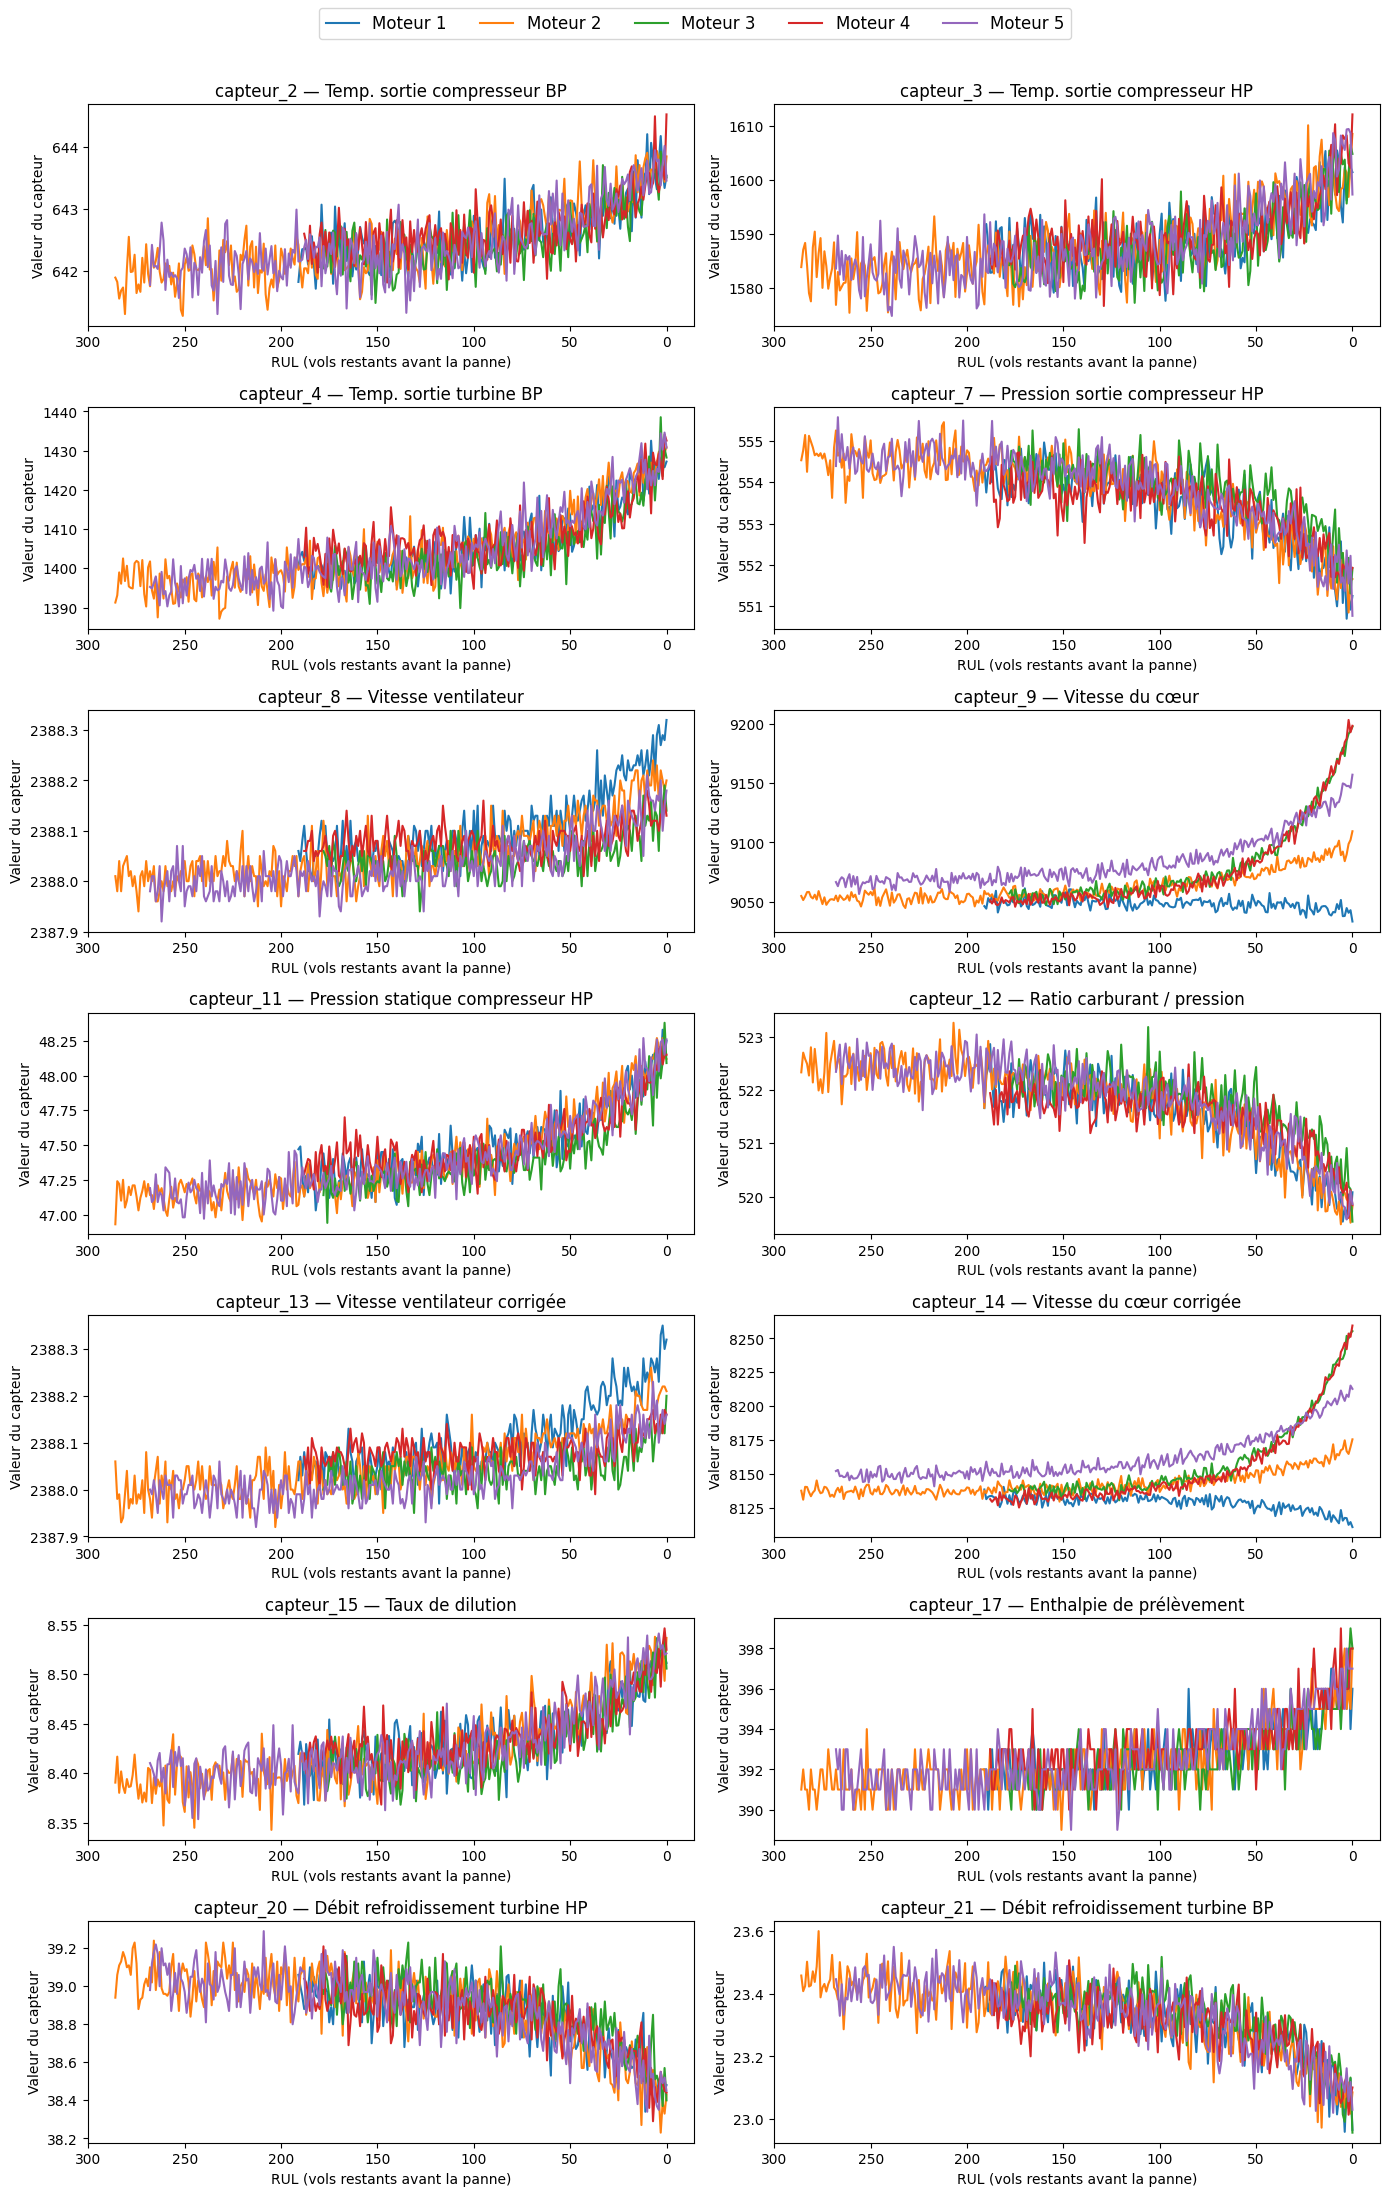

In [15]:
noms = {
    "capteur_2": "Temp. sortie compresseur BP", "capteur_3": "Temp. sortie compresseur HP",
    "capteur_4": "Temp. sortie turbine BP", "capteur_7": "Pression sortie compresseur HP",
    "capteur_8": "Vitesse ventilateur", "capteur_9": "Vitesse du cœur",
    "capteur_11": "Pression statique compresseur HP", "capteur_12": "Ratio carburant / pression",
    "capteur_13": "Vitesse ventilateur corrigée", "capteur_14": "Vitesse du cœur corrigée",
    "capteur_15": "Taux de dilution", "capteur_17": "Enthalpie de prélèvement",
    "capteur_20": "Débit refroidissement turbine HP", "capteur_21": "Débit refroidissement turbine BP",
}

fig, axes = plt.subplots(7, 2, figsize=(14, 22))

for ax, capteur in zip(axes.flatten(), capteurs_utiles):
    for m in [1, 2, 3, 4, 5]:
        donnees = train[train["moteur"] == m]
        ax.plot(donnees["RUL"], donnees[capteur], label=f"Moteur {m}")
    ax.set_title(f"{capteur} — {noms[capteur]}")
    ax.set_xlabel("RUL (vols restants avant la panne)")
    ax.set_ylabel("Valeur du capteur")
    ax.invert_xaxis()

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

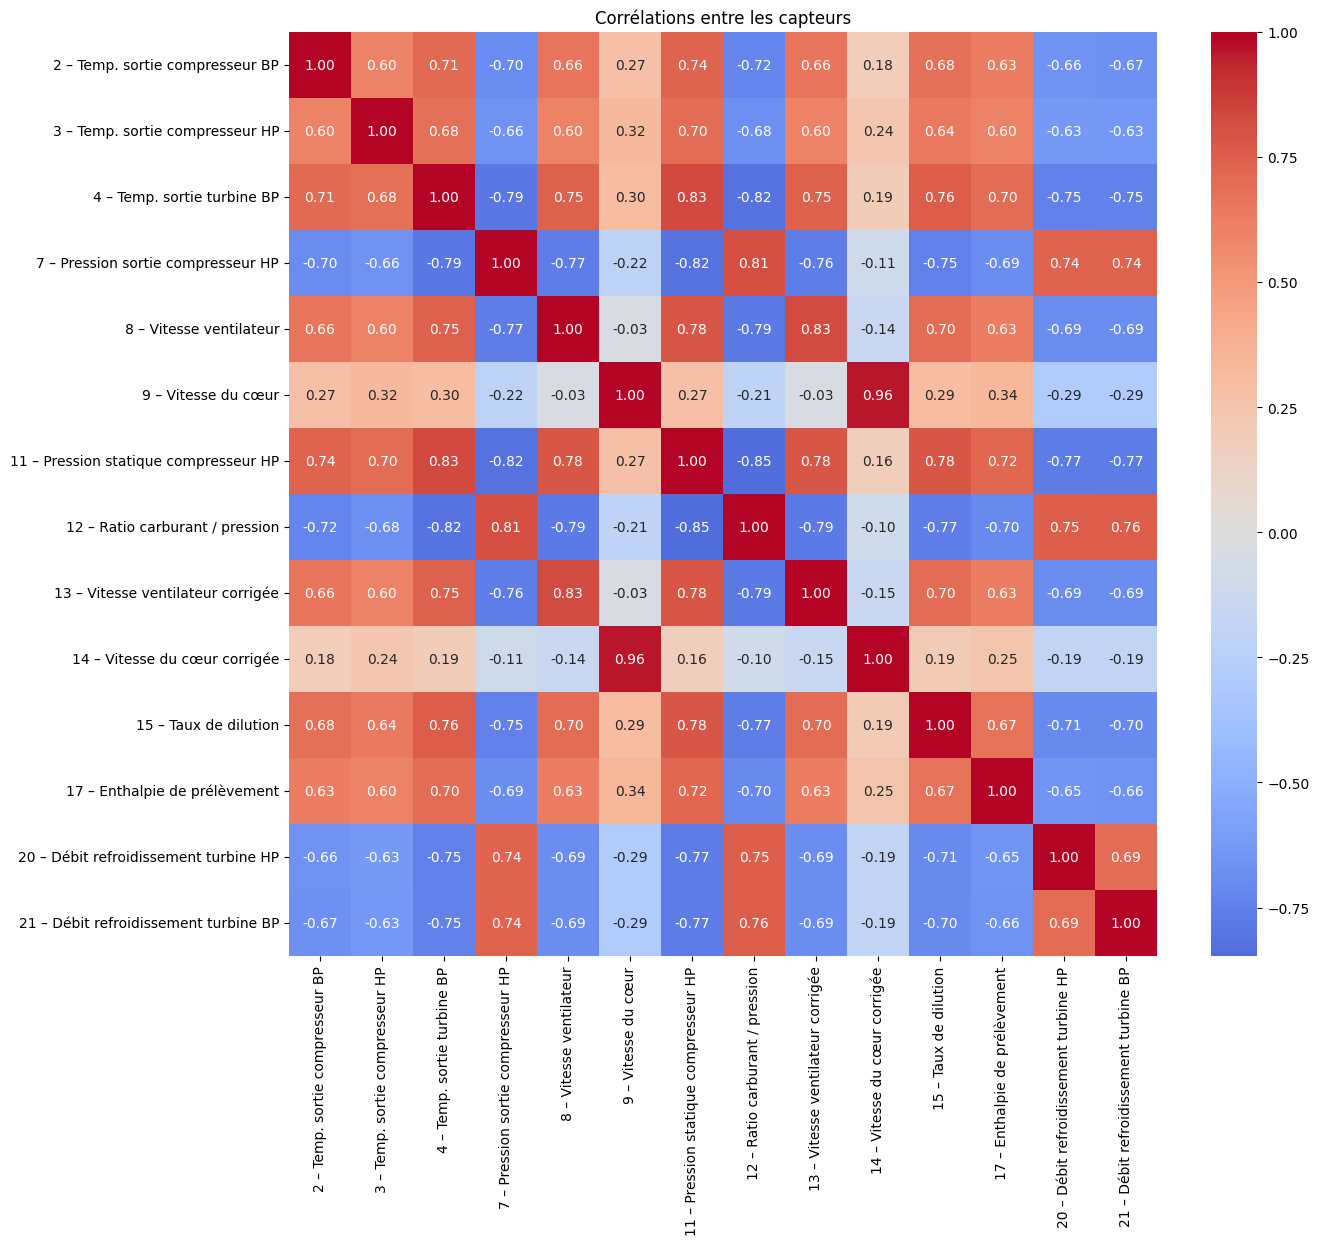

In [16]:
import seaborn as sns

etiquettes = {c: f"{c.split('_')[1]} – {noms[c]}" for c in capteurs_utiles}

plt.figure(figsize=(14, 12))
sns.heatmap(train[capteurs_utiles].rename(columns=etiquettes).corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations entre les capteurs")
plt.show()

In [17]:
train["RUL"] = train["RUL"].clip(upper=125)

print("RUL maximale :", train["RUL"].max())

RUL maximale : 125


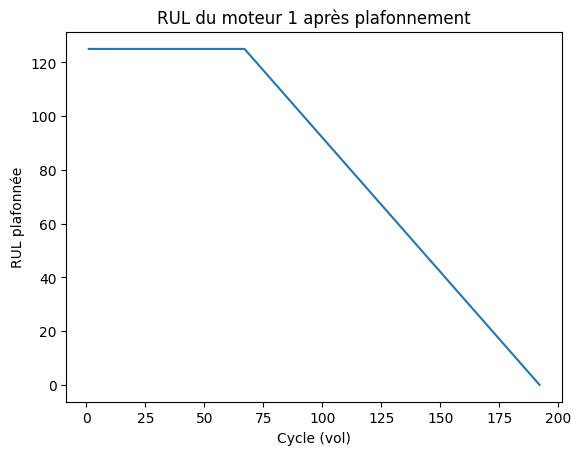

In [18]:
moteur_1 = train[train["moteur"] == 1]

plt.plot(moteur_1["cycle"], moteur_1["RUL"])
plt.xlabel("Cycle (vol)")
plt.ylabel("RUL plafonnée")
plt.title("RUL du moteur 1 après plafonnement")
plt.show()

In [19]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
train[capteurs_utiles] = scaler.fit_transform(train[capteurs_utiles])

train[capteurs_utiles].describe().loc[["min", "max"]]

,capteur_2,capteur_3,capteur_4,capteur_7,capteur_8,capteur_9,capteur_11,capteur_12,capteur_13,capteur_14,capteur_15,capteur_17,capteur_20,capteur_21
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [20]:
for c in capteurs_utiles:
    train[c + "_moy"] = train.groupby("moteur")[c].transform(
        lambda x: x.rolling(window=5, min_periods=1).mean())

print(train.shape)

(20631, 41)


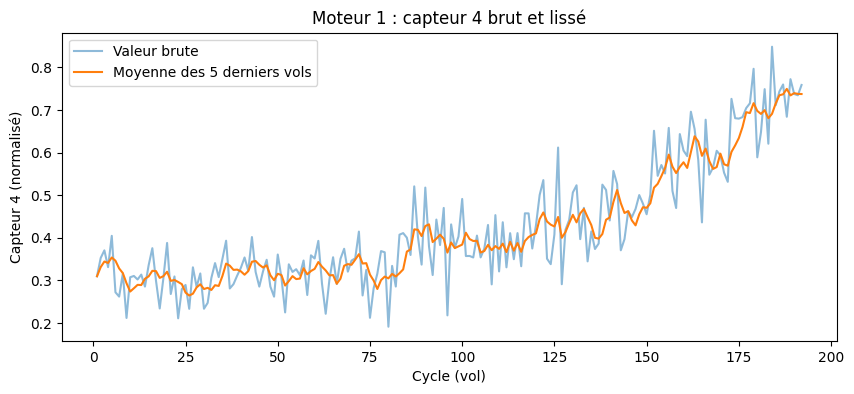

In [21]:
moteur_1 = train[train["moteur"] == 1]

plt.figure(figsize=(10, 4))
plt.plot(moteur_1["cycle"], moteur_1["capteur_4"], label="Valeur brute", alpha=0.5)
plt.plot(moteur_1["cycle"], moteur_1["capteur_4_moy"], label="Moyenne des 5 derniers vols")
plt.xlabel("Cycle (vol)")
plt.ylabel("Capteur 4 (normalisé)")
plt.title("Moteur 1 : capteur 4 brut et lissé")
plt.legend()
plt.show()

In [22]:
test = pd.read_csv(os.path.join(dossier, "test_FD001.txt"),
                   sep=r"\s+", header=None, names=colonnes)

rul_vraie = pd.read_csv(os.path.join(dossier, "RUL_FD001.txt"),
                        sep=r"\s+", header=None, names=["RUL_vraie"])

print("Test :", test.shape)
print("Réponses :", rul_vraie.shape)
rul_vraie.head()

Test : (13096, 26)
Réponses : (100, 1)


,RUL_vraie
0,112
1,98
2,69
3,82
4,91


In [23]:
test[capteurs_utiles] = scaler.transform(test[capteurs_utiles])

for c in capteurs_utiles:
    test[c + "_moy"] = test.groupby("moteur")[c].transform(
        lambda x: x.rolling(window=5, min_periods=1).mean())

In [24]:
test_final = test.groupby("moteur").last().reset_index()

print(test_final.shape)

(100, 40)


In [25]:
variables = capteurs_utiles + [c + "_moy" for c in capteurs_utiles]

X_train = train[variables]
y_train = train["RUL"]

print(X_train.shape, y_train.shape)

(20631, 28) (20631,)


In [26]:
from xgboost import XGBRegressor

modele = XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05)
modele.fit(X_train, y_train)

print("Modèle entraîné !")

Modèle entraîné !


In [27]:
X_test = test_final[variables]
predictions = modele.predict(X_test)

y_test = rul_vraie["RUL_vraie"].clip(upper=125)

resultats = pd.DataFrame({"moteur": test_final["moteur"],
                          "RUL_vraie": y_test,
                          "RUL_predite": predictions.round()})
resultats.head(10)

,moteur,RUL_vraie,RUL_predite
0,1,112,121.0
1,2,98,122.0
2,3,69,44.0
3,4,82,91.0
4,5,91,107.0
5,6,93,111.0
6,7,91,100.0
7,8,95,102.0
8,9,111,111.0
9,10,96,111.0


In [28]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(mean_squared_error(y_test, predictions))
print("RMSE :", round(rmse, 1), "vols")

RMSE : 17.1 vols


In [29]:
def score_nasa(vraie, predite):
    ecart = predite - vraie
    penalites = np.where(ecart < 0,
                         np.exp(-ecart / 13) - 1,
                         np.exp(ecart / 10) - 1)
    return penalites.sum()

print("Score NASA :", round(score_nasa(y_test.values, predictions)))

Score NASA : 857


In [30]:
resultats["ecart"] = resultats["RUL_predite"] - resultats["RUL_vraie"]
resultats.sort_values("ecart", ascending=False).head(5)

,moteur,RUL_vraie,RUL_predite,ecart
78,79,63,119.0,56.0
36,37,21,67.0,46.0
26,27,66,111.0,45.0
17,18,28,72.0,44.0
40,41,18,53.0,35.0
